# Learner Demographics and Course Enrollment Behavior Analysis on EduPro

## Project Objective
This project analyzes learner demographics and course enrollment behavior on the EduPro online learning platform.

The analysis focuses on:
- Learner age distribution
- Gender participation
- Enrollment behavior across age groups
- Course category preferences
- Course type and course level preferences
- Demographic differences in course selection
- Average courses taken per learner
- Enrollment concentration among active learners
- Beginner versus advanced learner behavior

This project is based on descriptive analytics and exploratory data analysis. It does not involve prediction or monetization analysis.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Data Loading

The EduPro analysis uses three datasets:

- **Users:** Contains learner demographic information such as age and gender.
- **Courses:** Contains course information including category, type, and level.
- **Transactions:** Contains learner enrollment transactions and connects learners with courses.

These datasets will later be integrated using `UserID` and `CourseID` to analyze learner demographics and enrollment behavior.

In [2]:
# Load the three datasets

users = pd.read_csv("/content/EduPro Online Platform.xlsx - Users.csv")
courses = pd.read_csv("/content/EduPro Online Platform.xlsx - Courses.csv")
transactions = pd.read_csv("/content/EduPro Online Platform.xlsx - Transactions.csv")

print("Datasets loaded successfully.")
print("Users shape:", users.shape)
print("Courses shape:", courses.shape)
print("Transactions shape:", transactions.shape)

Datasets loaded successfully.
Users shape: (3000, 5)
Courses shape: (60, 8)
Transactions shape: (10000, 7)


## 2. Initial Dataset Inspection

Before performing data cleaning and integration, the structure and sample records of each dataset are examined.

This step helps to:

- Verify that the required columns are available.
- Understand the structure of the Users, Courses, and Transactions datasets.
- Identify the variables required for demographic and enrollment analysis.
- Confirm that the datasets are suitable for integration using `UserID` and `CourseID`.

In [3]:
# Display column names of each dataset

print("USERS COLUMNS")
print(users.columns.tolist())

print("\nCOURSES COLUMNS")
print(courses.columns.tolist())

print("\nTRANSACTIONS COLUMNS")
print(transactions.columns.tolist())

USERS COLUMNS
['UserID', 'UserName', 'Age', 'Gender', 'Email']

COURSES COLUMNS
['CourseID', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

TRANSACTIONS COLUMNS
['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID']


In [4]:
# Display first five records from each dataset

print("USERS DATASET")
display(users.head())

print("\nCOURSES DATASET")
display(courses.head())

print("\nTRANSACTIONS DATASET")
display(transactions.head())

USERS DATASET


,UserID,UserName,Age,Gender,Email
0,U00001,wilsonjordan,15,Male,patricia27@hotmail.com
1,U00002,angela22,29,Female,hallrandy@hotmail.com
2,U00003,morrisonamanda,33,Female,ganderson@yahoo.com
3,U00004,fthornton,23,Female,christensencatherine@outlook.com
4,U00005,fostergeoffrey,21,Male,karenfuentes@yahoo.com



COURSES DATASET


,CourseID,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,CR00001,Python Basics,Programming,Paid,Beginner,472.28,11.00,4.74
1,CR00002,Java Programming,Programming,Free,Intermediate,0.00,37.70,2.43
2,CR00003,C++ for Beginners,Programming,Free,Beginner,0.00,19.53,3.85
3,CR00004,Advanced Python,Programming,Free,Beginner,0.00,45.13,2.88
4,CR00005,Full Stack Development,Programming,Free,Beginner,0.00,28.68,1.28



TRANSACTIONS DATASET


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID
0,TT00001,U00003,CR00016,25/10/2025,0.0,PayPal,TC00040
1,TT00002,U00003,CR00037,13/1/2025,0.0,PayPal,TC00040
2,TT00003,U00003,CR00019,28/3/2025,0.0,Bank Transfer,TC00040
3,TT00004,U00004,CR00048,2/6/2025,0.0,Bank Transfer,TC00040
4,TT00005,U00004,CR00060,10/8/2025,0.0,PayPal,TC00042


## 3. Data Quality Check

Check missing values and duplicate records before data integration.

In [5]:
# Check missing values

print("Missing Values - Users")
print(users.isnull().sum())

print("\nMissing Values - Courses")
print(courses.isnull().sum())

print("\nMissing Values - Transactions")
print(transactions.isnull().sum())

Missing Values - Users
UserID      0
UserName    0
Age         0
Gender      0
Email       0
dtype: int64

Missing Values - Courses
CourseID          0
CourseName        0
CourseCategory    0
CourseType        0
CourseLevel       0
CoursePrice       0
CourseDuration    0
CourseRating      0
dtype: int64

Missing Values - Transactions
TransactionID      0
UserID             0
CourseID           0
TransactionDate    0
Amount             0
PaymentMethod      0
TeacherID          0
dtype: int64


In [6]:
# Check duplicate records

print("Duplicate rows in Users:", users.duplicated().sum())
print("Duplicate rows in Courses:", courses.duplicated().sum())
print("Duplicate rows in Transactions:", transactions.duplicated().sum())

# Check duplicate primary IDs

print("\nDuplicate UserIDs:", users["UserID"].duplicated().sum())
print("Duplicate CourseIDs:", courses["CourseID"].duplicated().sum())
print("Duplicate TransactionIDs:", transactions["TransactionID"].duplicated().sum())

Duplicate rows in Users: 0
Duplicate rows in Courses: 0
Duplicate rows in Transactions: 0

Duplicate UserIDs: 0
Duplicate CourseIDs: 0
Duplicate TransactionIDs: 0


In [7]:
# Check data types

print("Users Data Types:")
print(users.dtypes)

print("\nCourses Data Types:")
print(courses.dtypes)

print("\nTransactions Data Types:")
print(transactions.dtypes)

Users Data Types:
UserID      object
UserName    object
Age          int64
Gender      object
Email       object
dtype: object

Courses Data Types:
CourseID           object
CourseName         object
CourseCategory     object
CourseType         object
CourseLevel        object
CoursePrice       float64
CourseDuration    float64
CourseRating      float64
dtype: object

Transactions Data Types:
TransactionID       object
UserID              object
CourseID            object
TransactionDate     object
Amount             float64
PaymentMethod       object
TeacherID           object
dtype: object


In [8]:
# Convert TransactionDate to datetime format

transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("TransactionDate type:", transactions["TransactionDate"].dtype)
print("Invalid dates:", transactions["TransactionDate"].isnull().sum())
print("Earliest transaction:", transactions["TransactionDate"].min())
print("Latest transaction:", transactions["TransactionDate"].max())

TransactionDate type: datetime64[ns]
Invalid dates: 0
Earliest transaction: 2025-01-01 00:00:00
Latest transaction: 2025-12-30 00:00:00


## 4. Referential Integrity Check

Before integrating the Users, Courses, and Transactions datasets, referential integrity is verified.

The Transactions dataset contains the relationships between learners and courses through:

- `UserID` → Users dataset
- `CourseID` → Courses dataset

The following checks verify whether every transaction references a valid learner and a valid course.

This ensures that the integrated dataset will not contain transactions associated with unknown learners or courses.

In [9]:
# ============================================
# 4. Referential Integrity Check
# ============================================

# Check whether every Transaction UserID exists in Users
invalid_user_ids = transactions[
    ~transactions["UserID"].isin(users["UserID"])
]

# Check whether every Transaction CourseID exists in Courses
invalid_course_ids = transactions[
    ~transactions["CourseID"].isin(courses["CourseID"])
]

print("REFERENTIAL INTEGRITY CHECK")
print("=" * 50)

print(f"Total transactions: {len(transactions):,}")

print(f"\nTransactions with invalid UserID: {len(invalid_user_ids):,}")
print(f"Transactions with invalid CourseID: {len(invalid_course_ids):,}")

# Display examples if invalid records exist
if len(invalid_user_ids) > 0:
    print("\nSample transactions with invalid UserID:")
    display(invalid_user_ids.head())

if len(invalid_course_ids) > 0:
    print("\nSample transactions with invalid CourseID:")
    display(invalid_course_ids.head())

REFERENTIAL INTEGRITY CHECK
Total transactions: 10,000

Transactions with invalid UserID: 0
Transactions with invalid CourseID: 0


## 5. Data Integration

The Users, Transactions, and Courses datasets are integrated into a single analytical dataset.

The integration is performed using:

- `UserID` to connect learners with their transactions
- `CourseID` to connect transactions with course information

A many-to-one relationship exists between Transactions and Users, and between Transactions and Courses.

The resulting dataset contains learner demographic information, course attributes, and enrollment transaction information in a single table.

This integrated dataset will be used for demographic analysis, enrollment analysis, and learner preference analysis.

In [10]:
# ============================================
# 5. Data Integration
# ============================================

# Merge Transactions with Users
analysis_df = transactions.merge(
    users,
    on="UserID",
    how="left"
)

# Merge the result with Courses
analysis_df = analysis_df.merge(
    courses,
    on="CourseID",
    how="left"
)

# Display basic information
print("INTEGRATED DATASET")
print("=" * 50)

print(f"Number of rows: {len(analysis_df):,}")
print(f"Number of columns: {len(analysis_df.columns):,}")

print("\nColumns:")
print(list(analysis_df.columns))

print("\nFirst 5 rows:")
display(analysis_df.head())

INTEGRATED DATASET
Number of rows: 10,000
Number of columns: 18

Columns:
['TransactionID', 'UserID', 'CourseID', 'TransactionDate', 'Amount', 'PaymentMethod', 'TeacherID', 'UserName', 'Age', 'Gender', 'Email', 'CourseName', 'CourseCategory', 'CourseType', 'CourseLevel', 'CoursePrice', 'CourseDuration', 'CourseRating']

First 5 rows:


,TransactionID,UserID,CourseID,TransactionDate,Amount,PaymentMethod,TeacherID,UserName,Age,Gender,Email,CourseName,CourseCategory,CourseType,CourseLevel,CoursePrice,CourseDuration,CourseRating
0,TT00001,U00003,CR00016,2025-10-25,0.0,PayPal,TC00040,morrisonamanda,33,Female,ganderson@yahoo.com,Digital Marketing,Marketing,Free,Intermediate,0.0,42.68,4.72
1,TT00002,U00003,CR00037,2025-01-13,0.0,PayPal,TC00040,morrisonamanda,33,Female,ganderson@yahoo.com,Scrum Essentials,Project Management,Free,Intermediate,0.0,33.93,3.45
2,TT00003,U00003,CR00019,2025-03-28,0.0,Bank Transfer,TC00040,morrisonamanda,33,Female,ganderson@yahoo.com,Content Marketing,Marketing,Free,Advanced,0.0,18.00,2.98
3,TT00004,U00004,CR00048,2025-06-02,0.0,Bank Transfer,TC00040,fthornton,23,Female,christensencatherine@outlook.com,AI Ethics,Artificial Intelligence,Free,Beginner,0.0,42.70,3.64
4,TT00005,U00004,CR00060,2025-08-10,0.0,PayPal,TC00042,fthornton,23,Female,christensencatherine@outlook.com,Content Creation,Digital Marketing,Free,Beginner,0.0,8.95,2.14


## 6. Learner Age Group Segmentation

To analyze enrollment behavior across different learner demographics, learners are segmented into five age groups:

- Under 18
- 18–25
- 26–35
- 36–45
- 45+

These age bands will be used throughout the analysis to compare enrollment behavior and course preferences across learner segments.

In [11]:
# ============================================
# 6. Learner Age Group Segmentation
# ============================================

def assign_age_group(age):
    if age < 18:
        return "Under 18"
    elif age <= 25:
        return "18–25"
    elif age <= 35:
        return "26–35"
    elif age <= 45:
        return "36–45"
    else:
        return "45+"


# Create AgeGroup column
analysis_df["AgeGroup"] = analysis_df["Age"].apply(assign_age_group)


# Define the correct logical order for the age groups
age_group_order = [
    "Under 18",
    "18–25",
    "26–35",
    "36–45",
    "45+"
]


# Convert AgeGroup to an ordered categorical variable
analysis_df["AgeGroup"] = pd.Categorical(
    analysis_df["AgeGroup"],
    categories=age_group_order,
    ordered=True
)


# Display age group distribution
age_group_distribution = (
    analysis_df["AgeGroup"]
    .value_counts()
    .sort_index()
    .reset_index()
)

age_group_distribution.columns = [
    "AgeGroup",
    "Enrollments"
]

print("AGE GROUP DISTRIBUTION")
print("=" * 50)

display(age_group_distribution)

AGE GROUP DISTRIBUTION


,AgeGroup,Enrollments
0,Under 18,1469
1,18–25,3732
2,26–35,4799
3,36–45,0
4,45+,0


## 7. Learner Demographic Overview

Analyze unique learners by age group and gender to understand EduPro's learner demographics.

In [12]:
# ============================================
# 7. Learner Demographic Overview
# ============================================

# --------------------------------------------
# 7.1 Unique learners by age group
# --------------------------------------------

learners_by_age = (
    analysis_df[["UserID", "AgeGroup"]]
    .drop_duplicates()
    .groupby("AgeGroup", observed=False)["UserID"]
    .nunique()
    .reset_index(name="UniqueLearners")
)

# Calculate percentage of learners
total_unique_learners = analysis_df["UserID"].nunique()

learners_by_age["Percentage"] = (
    learners_by_age["UniqueLearners"] /
    total_unique_learners * 100
).round(2)


print("UNIQUE LEARNERS BY AGE GROUP")
print("=" * 50)

display(learners_by_age)


# --------------------------------------------
# 7.2 Unique learners by gender
# --------------------------------------------

learners_by_gender = (
    analysis_df[["UserID", "Gender"]]
    .drop_duplicates()
    .groupby("Gender")["UserID"]
    .nunique()
    .reset_index(name="UniqueLearners")
)

# Calculate percentage of learners
learners_by_gender["Percentage"] = (
    learners_by_gender["UniqueLearners"] /
    total_unique_learners * 100
).round(2)


print("\nUNIQUE LEARNERS BY GENDER")
print("=" * 50)

display(learners_by_gender)


# --------------------------------------------
# 7.3 Overall learner count
# --------------------------------------------

print("\nOVERALL LEARNER COUNT")
print("=" * 50)

print(f"Total unique learners: {total_unique_learners:,}")

UNIQUE LEARNERS BY AGE GROUP


,AgeGroup,UniqueLearners,Percentage
0,Under 18,433,14.43
1,18–25,1121,37.37
2,26–35,1446,48.20
3,36–45,0,0.00
4,45+,0,0.00



UNIQUE LEARNERS BY GENDER


,Gender,UniqueLearners,Percentage
0,Female,1520,50.67
1,Male,1480,49.33



OVERALL LEARNER COUNT
Total unique learners: 3,000


## 8. Enrollment Distribution by Course Category

Analyze enrollment patterns across course categories.

In [13]:
# ============================================
# 8. Enrollment by Course Category
# ============================================

category_enrollment = (
    analysis_df["CourseCategory"]
    .value_counts()
    .reset_index()
)

category_enrollment.columns = [
    "CourseCategory",
    "Enrollments"
]

category_enrollment["Percentage"] = (
    category_enrollment["Enrollments"] /
    len(analysis_df) * 100
).round(2)

print("ENROLLMENTS BY COURSE CATEGORY")
print("=" * 50)

display(category_enrollment)

ENROLLMENTS BY COURSE CATEGORY


,CourseCategory,Enrollments,Percentage
0,Data Science,916,9.16
1,Finance,864,8.64
2,Web Development,844,8.44
3,Business,833,8.33
4,Artificial Intelligence,829,8.29
5,Project Management,829,8.29
6,Design,827,8.27
7,Cybersecurity,819,8.19
8,Machine Learning,819,8.19
9,Digital Marketing,808,8.08


## 9. Enrollment by Course Type

Analyze enrollment patterns across different course types.

In [14]:
# ============================================
# 9. Enrollment by Course Type
# ============================================

type_enrollment = (
    analysis_df["CourseType"]
    .value_counts()
    .reset_index()
)

type_enrollment.columns = [
    "CourseType",
    "Enrollments"
]

type_enrollment["Percentage"] = (
    type_enrollment["Enrollments"] /
    len(analysis_df) * 100
).round(2)

print("ENROLLMENTS BY COURSE TYPE")
print("=" * 50)

display(type_enrollment)

ENROLLMENTS BY COURSE TYPE


,CourseType,Enrollments,Percentage
0,Free,6403,64.03
1,Paid,3597,35.97


## 10. Enrollment by Course Level

Analyze enrollment distribution across beginner, intermediate, and advanced courses.

In [15]:
# ============================================
# 10. Enrollment by Course Level
# ============================================

level_enrollment = (
    analysis_df["CourseLevel"]
    .value_counts()
    .reset_index()
)

level_enrollment.columns = [
    "CourseLevel",
    "Enrollments"
]

level_enrollment["Percentage"] = (
    level_enrollment["Enrollments"] /
    len(analysis_df) * 100
).round(2)

print("ENROLLMENTS BY COURSE LEVEL")
print("=" * 50)

display(level_enrollment)

ENROLLMENTS BY COURSE LEVEL


,CourseLevel,Enrollments,Percentage
0,Beginner,3573,35.73
1,Advanced,3475,34.75
2,Intermediate,2952,29.52


## 11. Enrollment by Age Group

Analyze enrollment patterns across learner age groups.

In [16]:
# ============================================
# 11. Enrollment by Age Group
# ============================================

age_enrollment = (
    analysis_df["AgeGroup"]
    .value_counts()
    .sort_index()
    .reset_index()
)

age_enrollment.columns = [
    "AgeGroup",
    "Enrollments"
]

age_enrollment["Percentage"] = (
    age_enrollment["Enrollments"] /
    len(analysis_df) * 100
).round(2)

print("ENROLLMENTS BY AGE GROUP")
print("=" * 50)

display(age_enrollment)

ENROLLMENTS BY AGE GROUP


,AgeGroup,Enrollments,Percentage
0,Under 18,1469,14.69
1,18–25,3732,37.32
2,26–35,4799,47.99
3,36–45,0,0.00
4,45+,0,0.00


## 12. Gender vs Course Category

Compare course category enrollments by gender.

In [17]:
# ============================================
# 12. Gender vs Course Category
# ============================================

gender_category = pd.crosstab(
    analysis_df["Gender"],
    analysis_df["CourseCategory"]
)

print("GENDER VS COURSE CATEGORY")
print("=" * 50)

display(gender_category)

GENDER VS COURSE CATEGORY


CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
Gender,,,,,,,,,,,,
Female,413,418,430,479,424,417,451,403,385,420,425,413
Male,416,415,389,437,403,391,413,416,421,386,404,431


## 13. Age Group vs Course Category

Compare course category enrollments across age groups.

In [18]:
# ============================================
# 13. Age Group vs Course Category
# ============================================

age_category = pd.crosstab(
    analysis_df["AgeGroup"],
    analysis_df["CourseCategory"]
)

print("AGE GROUP VS COURSE CATEGORY")
print("=" * 50)

display(age_category)

AGE GROUP VS COURSE CATEGORY


CourseCategory,Artificial Intelligence,Business,Cybersecurity,Data Science,Design,Digital Marketing,Finance,Machine Learning,Marketing,Programming,Project Management,Web Development
AgeGroup,,,,,,,,,,,,
Under 18,129,120,121,114,120,127,136,120,126,109,115,132
18–25,317,307,307,343,311,296,297,305,313,305,296,335
26–35,383,406,391,459,396,385,431,394,367,392,418,377


## 14. Age Group × Course Category Heatmap

Visualize enrollment patterns across age groups and course categories.

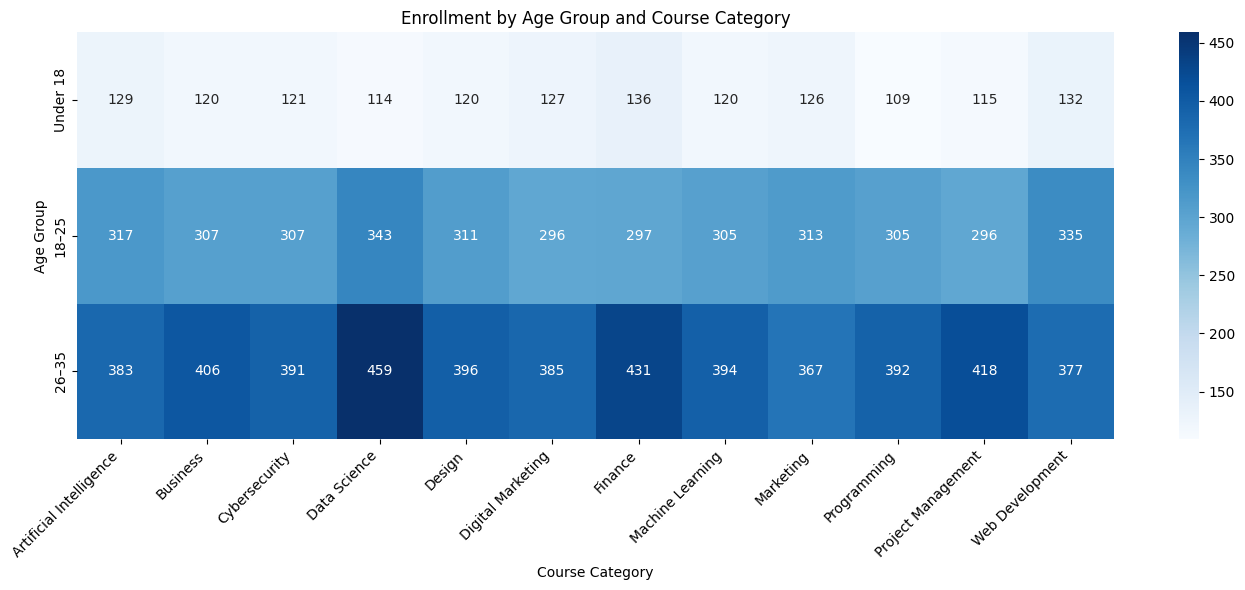

In [19]:
# ============================================
# 14. Age Group × Course Category Heatmap
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.heatmap(
    age_category,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Enrollment by Age Group and Course Category")
plt.xlabel("Course Category")
plt.ylabel("Age Group")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 15. Gender vs Course Level

Compare course-level enrollments by gender.

In [20]:
# ============================================
# 15. Gender vs Course Level
# ============================================

gender_level = pd.crosstab(
    analysis_df["Gender"],
    analysis_df["CourseLevel"]
)

print("GENDER VS COURSE LEVEL")
print("=" * 50)

display(gender_level)

GENDER VS COURSE LEVEL


CourseLevel,Advanced,Beginner,Intermediate
Gender,,,
Female,1758,1811,1509
Male,1717,1762,1443


## 16. Age Group vs Course Level

Compare course-level enrollments across age groups.

In [21]:
# ============================================
# 16. Age Group vs Course Level
# ============================================

age_level = pd.crosstab(
    analysis_df["AgeGroup"],
    analysis_df["CourseLevel"]
)

print("AGE GROUP VS COURSE LEVEL")
print("=" * 50)

display(age_level)

AGE GROUP VS COURSE LEVEL


CourseLevel,Advanced,Beginner,Intermediate
AgeGroup,,,
Under 18,534,501,434
18–25,1300,1345,1087
26–35,1641,1727,1431


## 17. Age Group vs Course Type

Compare course-type enrollments across age groups.

In [22]:
# ============================================
# 17. Age Group vs Course Type
# ============================================

age_type = pd.crosstab(
    analysis_df["AgeGroup"],
    analysis_df["CourseType"]
)

print("AGE GROUP VS COURSE TYPE")
print("=" * 50)

display(age_type)

AGE GROUP VS COURSE TYPE


CourseType,Free,Paid
AgeGroup,,
Under 18,907,562
18–25,2411,1321
26–35,3085,1714


## 18. Average Courses per Learner

Measure the average number of course enrollments per learner.

In [23]:
# ============================================
# 18. Average Courses per Learner
# ============================================

courses_per_learner = (
    analysis_df.groupby("UserID")
    .size()
)

print("COURSES PER LEARNER")
print("=" * 50)

print(f"Total unique learners: {courses_per_learner.count():,}")
print(f"Total enrollments: {courses_per_learner.sum():,}")
print(f"Average courses per learner: {courses_per_learner.mean():.2f}")
print(f"Median courses per learner: {courses_per_learner.median():.2f}")
print(f"Minimum courses taken: {courses_per_learner.min():,}")
print(f"Maximum courses taken: {courses_per_learner.max():,}")

COURSES PER LEARNER
Total unique learners: 3,000
Total enrollments: 10,000
Average courses per learner: 3.33
Median courses per learner: 1.00
Minimum courses taken: 1
Maximum courses taken: 16


## 19. Enrollment Concentration

Analyze how course enrollments are distributed across learners.

In [24]:
# ============================================
# 19. Enrollment Concentration
# ============================================

enrollment_counts = (
    analysis_df.groupby("UserID")
    .size()
    .reset_index(name="CoursesTaken")
)

enrollment_distribution = (
    enrollment_counts["CoursesTaken"]
    .value_counts()
    .sort_index()
    .reset_index()
)

enrollment_distribution.columns = [
    "CoursesTaken",
    "Learners"
]

enrollment_distribution["Percentage"] = (
    enrollment_distribution["Learners"] /
    len(enrollment_counts) * 100
).round(2)

print("ENROLLMENT CONCENTRATION")
print("=" * 50)

display(enrollment_distribution)

ENROLLMENT CONCENTRATION


,CoursesTaken,Learners,Percentage
0,1,1620,54.00
1,2,612,20.40
2,3,186,6.20
3,4,128,4.27
4,9,1,0.03
5,10,4,0.13
6,11,31,1.03
7,12,72,2.40
8,13,122,4.07
9,14,132,4.40


## 20. Learner Activity Segmentation

Group learners by the number of courses taken to examine enrollment concentration.

In [25]:
# ============================================
# 20. Learner Activity Segmentation
# ============================================

def classify_activity(courses):
    if courses == 1:
        return "1 Course"
    elif courses == 2:
        return "2 Courses"
    elif courses <= 4:
        return "3–4 Courses"
    elif courses <= 10:
        return "5–10 Courses"
    else:
        return "11+ Courses"


enrollment_counts["ActivitySegment"] = (
    enrollment_counts["CoursesTaken"]
    .apply(classify_activity)
)

activity_order = [
    "1 Course",
    "2 Courses",
    "3–4 Courses",
    "5–10 Courses",
    "11+ Courses"
]

activity_distribution = (
    enrollment_counts["ActivitySegment"]
    .value_counts()
    .reindex(activity_order, fill_value=0)
    .reset_index()
)

activity_distribution.columns = [
    "ActivitySegment",
    "Learners"
]

activity_distribution["Percentage"] = (
    activity_distribution["Learners"] /
    len(enrollment_counts) * 100
).round(2)

print("LEARNER ACTIVITY SEGMENTS")
print("=" * 50)

display(activity_distribution)

LEARNER ACTIVITY SEGMENTS


,ActivitySegment,Learners,Percentage
0,1 Course,1620,54.00
1,2 Courses,612,20.40
2,3–4 Courses,314,10.47
3,5–10 Courses,5,0.17
4,11+ Courses,449,14.97


## 21. Beginner vs Advanced Learner Behavior

Compare learner behavior across beginner and advanced course enrollments.

In [26]:
# ============================================
# 21. Beginner vs Advanced Learner Behavior
# ============================================

beginner_advanced = (
    analysis_df[
        analysis_df["CourseLevel"].isin(["Beginner", "Advanced"])
    ]
    .groupby("CourseLevel")
    .agg(
        Enrollments=("TransactionID", "count"),
        UniqueLearners=("UserID", "nunique"),
        AvgAge=("Age", "mean")
    )
    .reset_index()
)

beginner_advanced["AvgAge"] = (
    beginner_advanced["AvgAge"].round(2)
)

print("BEGINNER VS ADVANCED LEARNER BEHAVIOR")
print("=" * 50)

display(beginner_advanced)

BEGINNER VS ADVANCED LEARNER BEHAVIOR


,CourseLevel,Enrollments,UniqueLearners,AvgAge
0,Advanced,3475,1608,24.85
1,Beginner,3573,1596,24.99


## 22. Key Performance Indicators

Summarize the main learner and enrollment KPIs.

In [27]:
# ============================================
# 22. Key Performance Indicators
# ============================================

# Total unique learners
total_learners = analysis_df["UserID"].nunique()

# Total enrollments
total_enrollments = len(analysis_df)

# Average courses per learner
average_courses = analysis_df.groupby("UserID").size().mean()

# Gender participation based on UNIQUE LEARNERS
gender_unique = (
    analysis_df[["UserID", "Gender"]]
    .drop_duplicates()
    .groupby("Gender")["UserID"]
    .nunique()
)

female_percentage = (
    gender_unique.get("Female", 0) / total_learners * 100
)

# Most popular course category
most_popular_category = category_enrollment.iloc[0]["CourseCategory"]

# Most popular course level
most_popular_level = level_enrollment.iloc[0]["CourseLevel"]

# Most popular course type
most_popular_type = type_enrollment.iloc[0]["CourseType"]


# Create KPI table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Enrollments",
        "Total Unique Learners",
        "Average Courses per Learner",
        "Female Participation",
        "Male Participation",
        "Most Popular Course Category",
        "Most Popular Course Level",
        "Most Popular Course Type"
    ],
    "Value": [
        total_enrollments,
        total_learners,
        round(average_courses, 2),
        f"{female_percentage:.2f}%",
        f"{100 - female_percentage:.2f}%",
        most_popular_category,
        most_popular_level,
        most_popular_type
    ]
})


# Display KPI summary
print("EDUPRO KPI SUMMARY")
print("=" * 50)

display(kpi_summary)

EDUPRO KPI SUMMARY


,KPI,Value
0,Total Enrollments,10000
1,Total Unique Learners,3000
2,Average Courses per Learner,3.33
3,Female Participation,50.67%
4,Male Participation,49.33%
5,Most Popular Course Category,Data Science
6,Most Popular Course Level,Beginner
7,Most Popular Course Type,Free


## 23. Course Category Popularity

Visualize enrollment distribution across course categories.

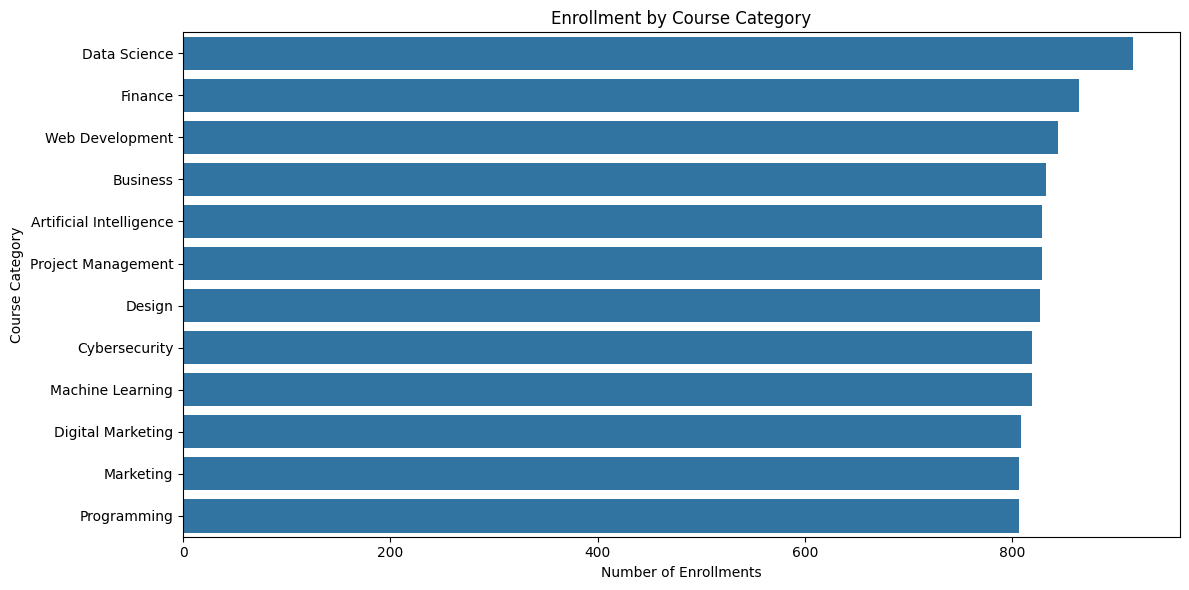

In [28]:
# ============================================
# 23. Course Category Popularity
# ============================================

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_enrollment,
    x="Enrollments",
    y="CourseCategory"
)

plt.title("Enrollment by Course Category")
plt.xlabel("Number of Enrollments")
plt.ylabel("Course Category")
plt.tight_layout()
plt.show()

## 24. Course Level Popularity

Visualize enrollment distribution across course levels.

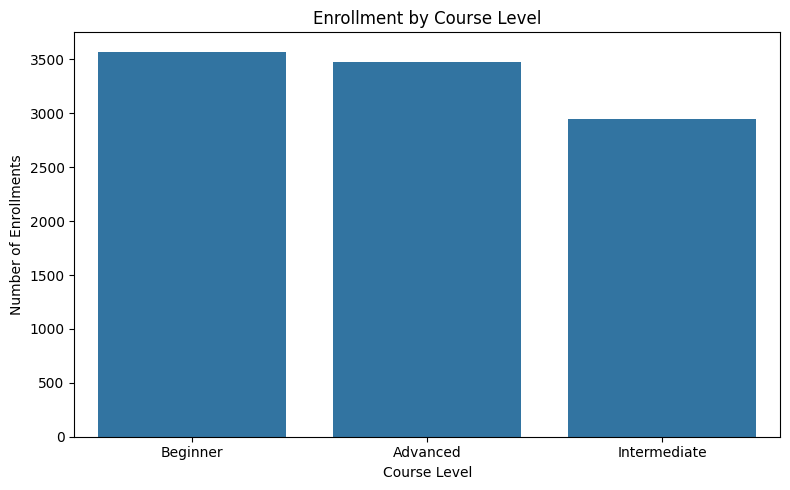

In [29]:
# ============================================
# 24. Course Level Popularity
# ============================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=level_enrollment,
    x="CourseLevel",
    y="Enrollments"
)

plt.title("Enrollment by Course Level")
plt.xlabel("Course Level")
plt.ylabel("Number of Enrollments")
plt.tight_layout()
plt.show()

## 25. Course Type Popularity

Visualize enrollment distribution across free and paid courses.

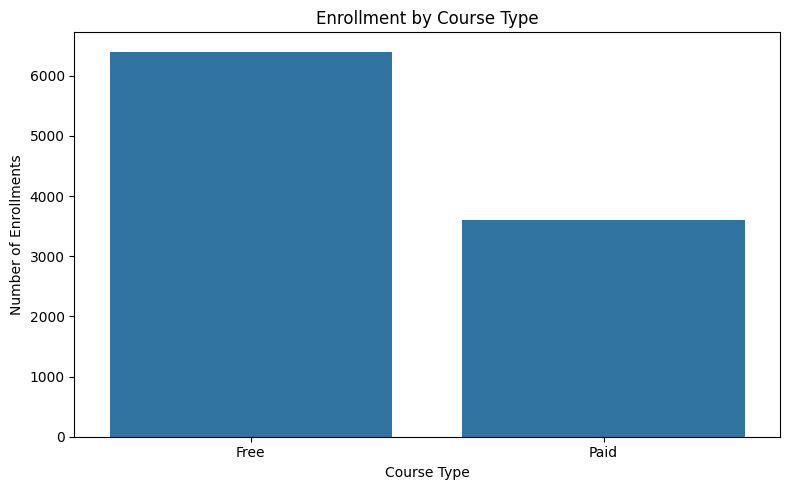

In [30]:
# ============================================
# 25. Course Type Popularity
# ============================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_enrollment,
    x="CourseType",
    y="Enrollments"
)

plt.title("Enrollment by Course Type")
plt.xlabel("Course Type")
plt.ylabel("Number of Enrollments")
plt.tight_layout()
plt.show()

## 26. Gender-Based Course Preferences

Visualize course category enrollment differences by gender.

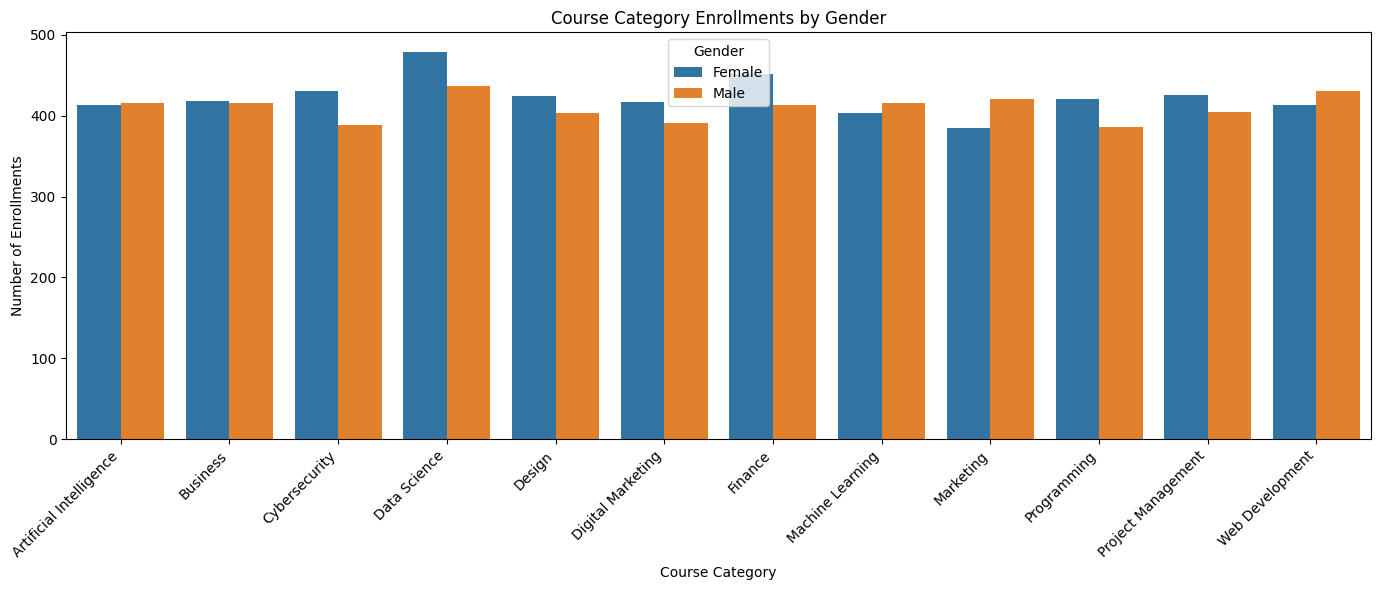

In [31]:
# Gender-based course category visualization

gender_category_plot = (
    gender_category
    .reset_index()
    .melt(
        id_vars="Gender",
        var_name="CourseCategory",
        value_name="Enrollments"
    )
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=gender_category_plot,
    x="CourseCategory",
    y="Enrollments",
    hue="Gender"
)

plt.title("Course Category Enrollments by Gender")
plt.xlabel("Course Category")
plt.ylabel("Number of Enrollments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 27. Gender vs Course Level

Visualize course-level enrollment differences by gender.

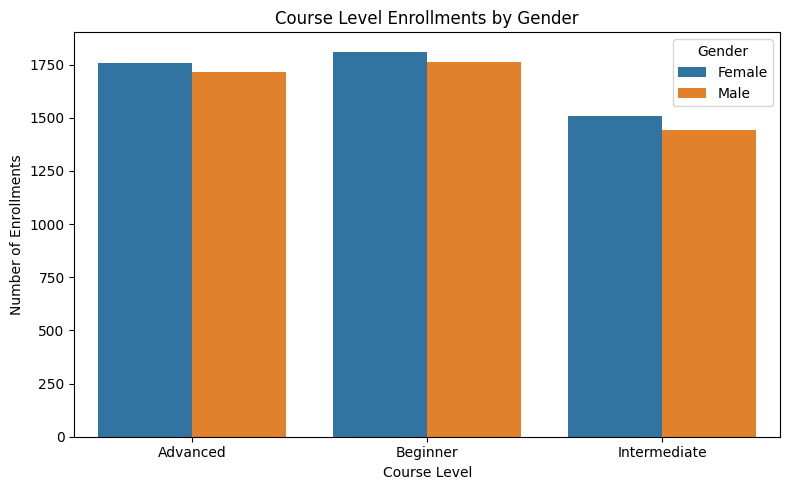

In [32]:
# Gender vs course level visualization

gender_level_plot = (
    gender_level
    .reset_index()
    .melt(
        id_vars="Gender",
        var_name="CourseLevel",
        value_name="Enrollments"
    )
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_level_plot,
    x="CourseLevel",
    y="Enrollments",
    hue="Gender"
)

plt.title("Course Level Enrollments by Gender")
plt.xlabel("Course Level")
plt.ylabel("Number of Enrollments")
plt.tight_layout()
plt.show()

## 28. Age Group × Course Level Heatmap

Visualize course-level preferences across age groups.

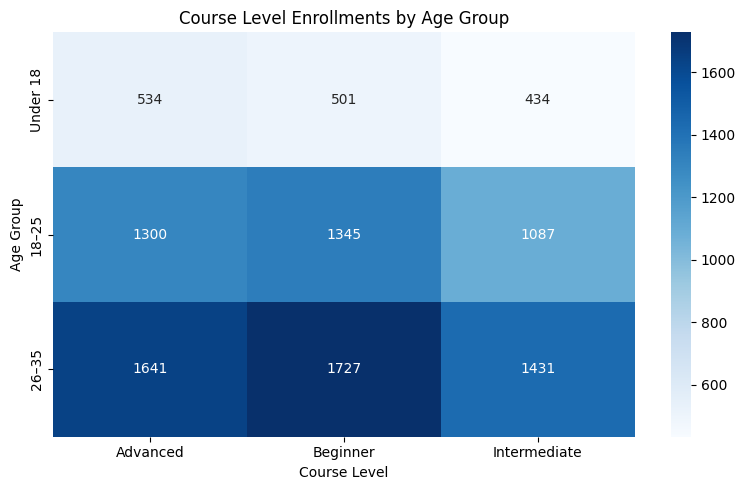

In [33]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    age_level,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Course Level Enrollments by Age Group")
plt.xlabel("Course Level")
plt.ylabel("Age Group")
plt.tight_layout()
plt.show()

## 29. Monthly Enrollment Trends

Analyze how course enrollments change over time.

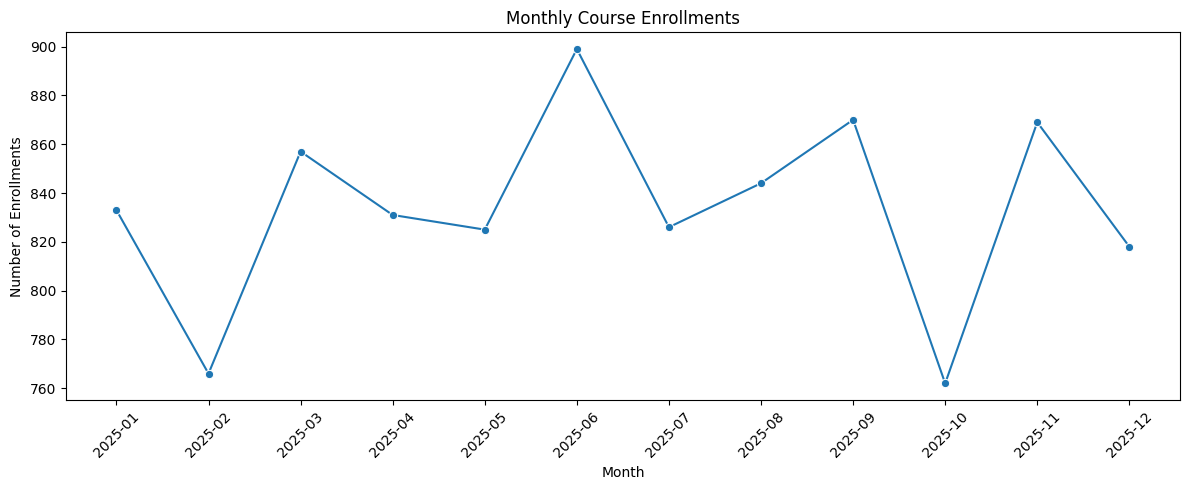

In [34]:
# Monthly enrollment trends

analysis_df["TransactionDate"] = pd.to_datetime(
    analysis_df["TransactionDate"]
)

analysis_df["EnrollmentMonth"] = (
    analysis_df["TransactionDate"].dt.to_period("M").astype(str)
)

monthly_enrollment = (
    analysis_df.groupby("EnrollmentMonth")
    .size()
    .reset_index(name="Enrollments")
    .sort_values("EnrollmentMonth")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_enrollment,
    x="EnrollmentMonth",
    y="Enrollments",
    marker="o"
)

plt.title("Monthly Course Enrollments")
plt.xlabel("Month")
plt.ylabel("Number of Enrollments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 30. Enrollment by Gender

Visualize total course enrollments by gender.

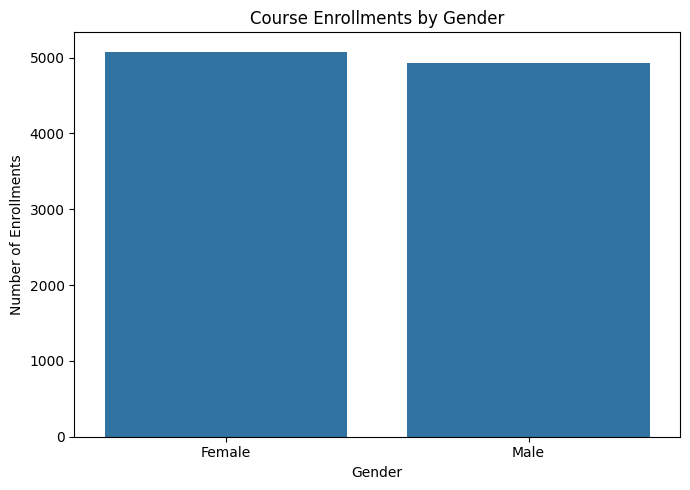

In [35]:
gender_enrollment = (
    analysis_df["Gender"]
    .value_counts()
    .rename_axis("Gender")
    .reset_index(name="Enrollments")
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_enrollment,
    x="Gender",
    y="Enrollments"
)

plt.title("Course Enrollments by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Enrollments")
plt.tight_layout()
plt.show()

## 31. Age Group Enrollment Distribution

Visualize course enrollments across learner age groups.

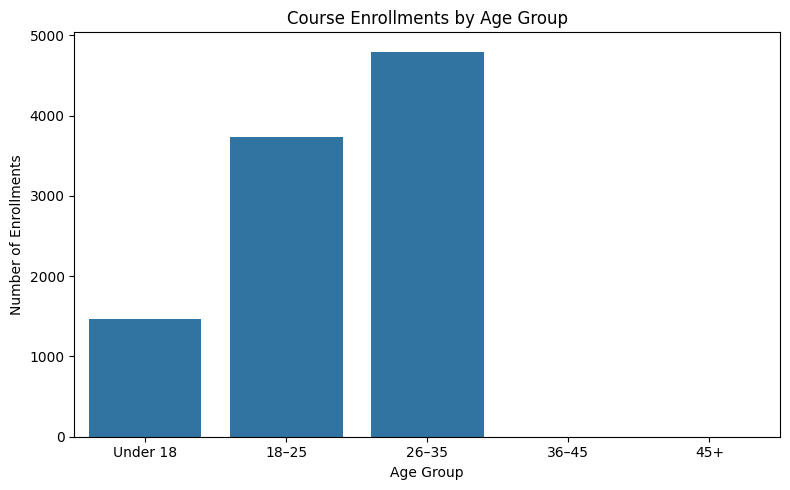

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_enrollment,
    x="AgeGroup",
    y="Enrollments"
)

plt.title("Course Enrollments by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Enrollments")
plt.tight_layout()
plt.show()

## 32. Enrollment Percentage by Age Group

Compare each age group's share of total enrollments.

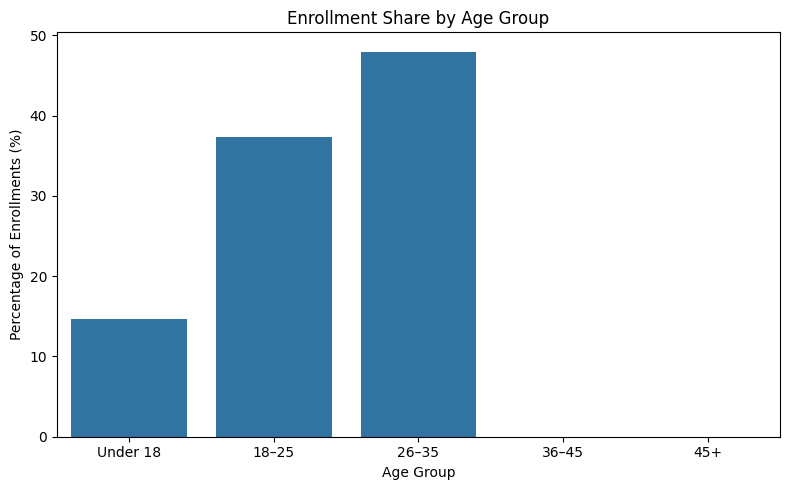

In [37]:
age_enrollment_plot = age_enrollment.copy()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=age_enrollment_plot,
    x="AgeGroup",
    y="Percentage"
)

plt.title("Enrollment Share by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Enrollments (%)")
plt.tight_layout()
plt.show()

## 33. Course Category vs Course Level

Compare enrollments across course categories and skill levels.

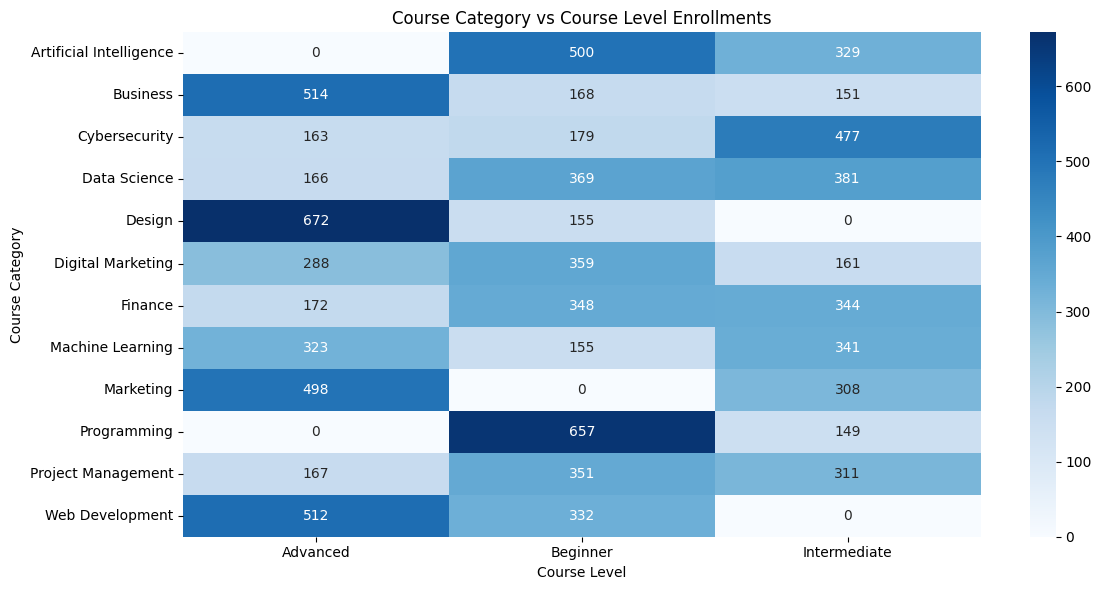

In [38]:
category_level = pd.crosstab(
    analysis_df["CourseCategory"],
    analysis_df["CourseLevel"]
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    category_level,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Course Category vs Course Level Enrollments")
plt.xlabel("Course Level")
plt.ylabel("Course Category")
plt.tight_layout()
plt.show()

## 34. Average Courses per Learner by Age Group

Compare average course enrollments across learner age groups.

,AgeGroup,AverageCourses
0,Under 18,3.39
1,18–25,3.33
2,26–35,3.32
3,36–45,NaN
4,45+,NaN


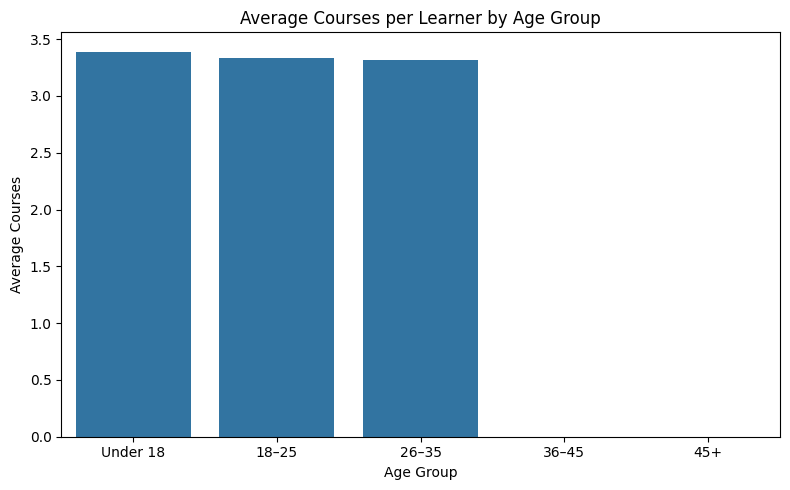

In [39]:
# Average courses per learner by age group

learner_course_counts = (
    analysis_df.groupby(["UserID", "AgeGroup"], observed=True)
    .size()
    .reset_index(name="CoursesTaken")
)

avg_courses_by_age = (
    learner_course_counts.groupby("AgeGroup", observed=False)
    ["CoursesTaken"]
    .mean()
    .reset_index(name="AverageCourses")
)

avg_courses_by_age["AverageCourses"] = (
    avg_courses_by_age["AverageCourses"].round(2)
)

display(avg_courses_by_age)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=avg_courses_by_age,
    x="AgeGroup",
    y="AverageCourses"
)

plt.title("Average Courses per Learner by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Courses")
plt.tight_layout()
plt.show()

## 35. Gender Participation

Compare the percentage of unique learners by gender.

,Gender,Learners,Percentage
0,Female,1520,50.67
1,Male,1480,49.33


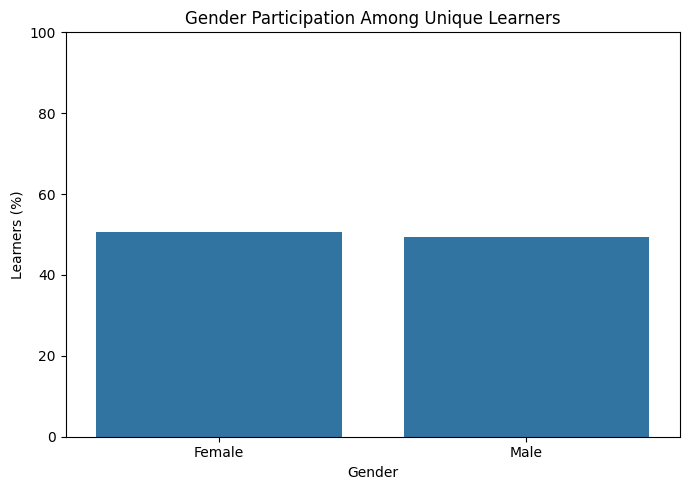

In [40]:
# Gender participation based on unique learners

gender_participation = (
    analysis_df[["UserID", "Gender"]]
    .drop_duplicates()
    ["Gender"]
    .value_counts()
    .rename_axis("Gender")
    .reset_index(name="Learners")
)

gender_participation["Percentage"] = (
    gender_participation["Learners"]
    / gender_participation["Learners"].sum()
    * 100
).round(2)

display(gender_participation)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_participation,
    x="Gender",
    y="Percentage"
)

plt.title("Gender Participation Among Unique Learners")
plt.xlabel("Gender")
plt.ylabel("Learners (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 36. Course Category Popularity Index

Calculate each course category's percentage of total enrollments.

In [41]:
# Course category popularity index

category_popularity = category_enrollment.copy()

category_popularity["PopularityIndex"] = (
    category_popularity["Enrollments"]
    / category_popularity["Enrollments"].sum()
    * 100
).round(2)

category_popularity = category_popularity.sort_values(
    "PopularityIndex",
    ascending=False
)

display(category_popularity)

,CourseCategory,Enrollments,Percentage,PopularityIndex
0,Data Science,916,9.16,9.16
1,Finance,864,8.64,8.64
2,Web Development,844,8.44,8.44
3,Business,833,8.33,8.33
4,Artificial Intelligence,829,8.29,8.29
5,Project Management,829,8.29,8.29
6,Design,827,8.27,8.27
7,Cybersecurity,819,8.19,8.19
8,Machine Learning,819,8.19,8.19
9,Digital Marketing,808,8.08,8.08


## 37. Course Level Preference Distribution

Calculate each course level's share of total enrollments.

In [42]:
# Course level preference distribution

level_preference = level_enrollment.copy()

level_preference["Percentage"] = (
    level_preference["Enrollments"]
    / level_preference["Enrollments"].sum()
    * 100
).round(2)

display(level_preference)

,CourseLevel,Enrollments,Percentage
0,Beginner,3573,35.73
1,Advanced,3475,34.75
2,Intermediate,2952,29.52


## 38. Key Findings

Summarize the main findings from learner demographics and enrollment analysis.

In [43]:
# Key findings summary

key_findings = pd.DataFrame({
    "Analysis": [
        "Total unique learners",
        "Total enrollments",
        "Largest age group",
        "Female participation",
        "Most popular category",
        "Most popular course level",
        "Most popular course type",
        "Average courses per learner"
    ],
    "Finding": [
        f"{analysis_df['UserID'].nunique():,} learners",
        f"{len(analysis_df):,} enrollments",
        "26–35 (48.20% of unique learners)",
        "50.67% female, 49.33% male",
        "Data Science (916 enrollments)",
        "Beginner (35.73%)",
        "Free (64.03%)",
        f"{courses_per_learner.mean():.2f}"
    ]
})

display(key_findings)

,Analysis,Finding
0,Total unique learners,"3,000 learners"
1,Total enrollments,"10,000 enrollments"
2,Largest age group,26–35 (48.20% of unique learners)
3,Female participation,"50.67% female, 49.33% male"
4,Most popular category,Data Science (916 enrollments)
5,Most popular course level,Beginner (35.73%)
6,Most popular course type,Free (64.03%)
7,Average courses per learner,3.33


## 39. Insights and Recommendations

Interpret the findings and recommend improvements to course planning, learner engagement, and inclusivity.

In [44]:
# Key insights and recommendations

insights = pd.DataFrame({
    "Finding": [
        "The 26–35 age group represents 48.20% of unique learners.",
        "Female and male participation is nearly balanced.",
        "Data Science is the most popular course category.",
        "Beginner courses have the highest enrollment share.",
        "Free courses account for 64.03% of enrollments.",
        "The median learner has enrolled in one course."
    ],
    "Recommendation": [
        "Review course offerings for relevance to the largest learner segment while serving all age groups.",
        "Continue inclusive outreach and monitor participation across genders.",
        "Review Data Science course capacity and explore related learning needs.",
        "Review beginner course availability and pathways to intermediate and advanced learning.",
        "Evaluate learner preferences for free courses and maintain accessible learning options.",
        "Explore ways to help learners discover relevant additional courses without pressuring them."
    ]
})

display(insights)

,Finding,Recommendation
0,The 26–35 age group represents 48.20% of uniqu...,Review course offerings for relevance to the l...
1,Female and male participation is nearly balanced.,Continue inclusive outreach and monitor partic...
2,Data Science is the most popular course category.,Review Data Science course capacity and explor...
3,Beginner courses have the highest enrollment s...,Review beginner course availability and pathwa...
4,Free courses account for 64.03% of enrollments.,Evaluate learner preferences for free courses ...
5,The median learner has enrolled in one course.,Explore ways to help learners discover relevan...


## 40. Analysis Coverage Check

Verify that the main demographic and course preference analyses are available.

In [45]:
# Analysis coverage check

required_analyses = {
    "Learner demographics": learners_by_age is not None and learners_by_gender is not None,
    "Course category enrollment": category_enrollment is not None,
    "Course type enrollment": type_enrollment is not None,
    "Course level enrollment": level_enrollment is not None,
    "Age group vs category": age_category is not None,
    "Gender vs category": gender_category is not None,
    "Gender vs course level": gender_level is not None,
    "Age group vs course level": age_level is not None,
    "Age group vs course type": age_type is not None,
    "Enrollment concentration": enrollment_distribution is not None,
    "KPI summary": kpi_summary is not None,
    "Insights and recommendations": insights is not None
}

coverage_df = pd.DataFrame(
    list(required_analyses.items()),
    columns=["Required Analysis", "Available"]
)

coverage_df["Status"] = coverage_df["Available"].map({
    True: "Available",
    False: "Missing"
})

display(coverage_df)

,Required Analysis,Available,Status
0,Learner demographics,True,Available
1,Course category enrollment,True,Available
2,Course type enrollment,True,Available
3,Course level enrollment,True,Available
4,Age group vs category,True,Available
5,Gender vs category,True,Available
6,Gender vs course level,True,Available
7,Age group vs course level,True,Available
8,Age group vs course type,True,Available
9,Enrollment concentration,True,Available


## 41. Prepare Data for Streamlit Dashboard

Select the fields required for interactive learner and enrollment analysis.

In [46]:
# Prepare dashboard dataset

dashboard_df = analysis_df[
    [
        "TransactionID",
        "UserID",
        "CourseID",
        "Age",
        "AgeGroup",
        "Gender",
        "CourseCategory",
        "CourseType",
        "CourseLevel",
        "TransactionDate"
    ]
].copy()

print("DASHBOARD DATASET")
print("=" * 40)
print("Rows:", dashboard_df.shape[0])
print("Columns:", dashboard_df.shape[1])

display(dashboard_df.head())

DASHBOARD DATASET
Rows: 10000
Columns: 10


,TransactionID,UserID,CourseID,Age,AgeGroup,Gender,CourseCategory,CourseType,CourseLevel,TransactionDate
0,TT00001,U00003,CR00016,33,26–35,Female,Marketing,Free,Intermediate,2025-10-25
1,TT00002,U00003,CR00037,33,26–35,Female,Project Management,Free,Intermediate,2025-01-13
2,TT00003,U00003,CR00019,33,26–35,Female,Marketing,Free,Advanced,2025-03-28
3,TT00004,U00004,CR00048,23,18–25,Female,Artificial Intelligence,Free,Beginner,2025-06-02
4,TT00005,U00004,CR00060,23,18–25,Female,Digital Marketing,Free,Beginner,2025-08-10


In [47]:
dashboard_df.to_csv("edupro_dashboard_data.csv", index=False)

from google.colab import files
files.download("edupro_dashboard_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>